<a href="https://colab.research.google.com/github/za-world-xd/physics-informed-neural-network-beam-project/blob/main/ITR02_forward_pinn_beam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VJTI FYP: Beam Damage Identification from Sparse Vibration Data
## Phase 1: Forward PINN (Fourier-Enhanced Euler–Bernoulli Cantilever Beam)


### Why Fourier Features & Curriculum Training are Critical:
In transient impact vibration, the beam responds with high-frequency modes (Mode 4 at $222\text{ Hz}$ and Mode 5 at $366\text{ Hz}$). Vanilla MLPs suffer from **spectral bias (F-Principle)** and get trapped in the **trivial zero solution** ($w = 0$), because setting all weights to zero makes the PDE residual zero.

This notebook overcomes the zero-solution failure by using:
1. **Multi-Scale Fourier Feature Embedding**: Temporal coordinates are projected onto sinusoidal basis functions covering $5\text{ Hz}$ to $420\text{ Hz}$.
2. **Two-Stage Curriculum Training**:
   - **Stage 1 (Epochs 1–1500)**: Warmup data-locking. The network prioritizes matching the actual acceleration signals ($S_1, S_2, S_3$), driving $R^2$ up from $0.0$ to $>0.90$.
   - **Stage 2 (Epochs 1501–3500)**: Physics injection. Ramps up the 4th-order Euler–Bernoulli PDE residual and cantilever boundary conditions to regularize the full field without collapsing to zero.
3. **Withheld Validation Sensor $R$ ($0.90L = 720\text{ mm}$)**: Blind prediction validation.



In [1]:
# Cell 1: Environment Setup & GPU Verification
import os
import math
import csv
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Active PyTorch backend: {device}")
if device.type == 'cuda':
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")

Active PyTorch backend: cuda
GPU Name: Tesla T4


In [2]:
# Cell 2: Dataset Verification (Upload prompt if running in a fresh Colab session)
HEALTHY_CSV = "Ansys Vibration Training Data - Transient Healthy.csv"
NOTCHED_CSV = "Ansys Vibration Training Data - Transient Notched.csv"

def check_or_upload_files():
    missing = [f for f in [HEALTHY_CSV, NOTCHED_CSV] if not os.path.exists(f)]
    if missing:
        print(f"Missing files: {missing}")
        try:
            from google.colab import files
            print("Please upload the missing CSV file(s) below:")
            uploaded = files.upload()
        except ImportError:
            print("Running locally: please place the CSV files in current working directory.")
    else:
        print("All ANSYS transient datasets are present:")
        for f in [HEALTHY_CSV, NOTCHED_CSV]:
            size_kb = os.path.getsize(f) / 1024
            print(f"  - {f} ({size_kb:.1f} KB)")

check_or_upload_files()

All ANSYS transient datasets are present:
  - Ansys Vibration Training Data - Transient Healthy.csv (26.9 KB)
  - Ansys Vibration Training Data - Transient Notched.csv (27.1 KB)


In [3]:
# Cell 3: Beam Specifications & Kapoor et al. (2024) Nondimensionalization
class BeamParameters:
    def __init__(self):
        # Physical beam geometry
        self.L = 0.800          # Free length (m) = 800 mm
        self.b = 0.025          # Width (m) = 25 mm
        self.h = 0.005          # Bending thickness (m) = 5 mm

        # Structural steel properties
        self.E0 = 205e9         # Young's modulus (Pa) = 205 GPa
        self.rho = 7850.0       # Density (kg/m^3)
        self.nu = 0.30          # Poisson's ratio
        self.damping_ratio = 0.005 # Structural damping (0.5%)

        # Derived cross-sectional properties
        self.A = self.b * self.h                           # 1.250e-4 m^2
        self.I0 = (self.b * (self.h**3)) / 12.0            # 2.60417e-10 m^4
        self.EI0 = self.E0 * self.I0                       # 53.3854 N.m^2
        self.mu = self.rho * self.A                        # 0.98125 kg/m
        self.mass_total = self.mu * self.L                 # 0.785 kg

        # Theoretical Cantilever Natural Frequencies (lambdas: 1.875, 4.694, 7.855)
        self.lambdas = [1.875104, 4.694091, 7.854757, 10.995541, 14.137168]
        self.natural_freqs_hz = [
            (lam**2 / (2.0 * math.pi * (self.L**2))) * math.sqrt(self.EI0 / self.mu)
            for lam in self.lambdas
        ]
        self.f1 = self.natural_freqs_hz[0]                 # ~6.449 Hz
        self.c = 2.0 * self.damping_ratio * (2.0 * math.pi * self.f1) * self.mu

        # Excitation parameters
        self.x_imp = 0.05 * self.L  # 0.040 m (40 mm, 5% L)
        self.F_peak = -10.0         # -10 N downward impact pulse
        self.t_impact = 0.001       # 1.0 ms duration (f(x,t) = 0 for t >= 0.001 s)

        # Sensor coordinates along beam (m)
        self.x_s1 = 0.10 * self.L   # 0.080 m (80 mm, 10% L)
        self.x_s2 = 0.50 * self.L   # 0.400 m (400 mm, 50% L)
        self.x_s3 = 0.80 * self.L   # 0.640 m (640 mm, 80% L)
        self.x_sR = 0.90 * self.L   # 0.720 m (720 mm, 90% L - Withheld Validation Sensor R)

        # Nondimensional scaling factors (Kapoor et al., 2024)
        self.x_scale = self.L
        self.t_scale = math.sqrt((self.mu * (self.L**4)) / self.EI0) # ~0.08676 s
        self.w_scale = 1.0e-3                              # 1 mm scale
        self.a_scale = self.w_scale / (self.t_scale**2)    # ~0.1328 m/s^2
        self.gamma_hat = (self.c * self.t_scale) / self.mu

params = BeamParameters()
print(f"Beam Configuration Verified:")
print(f"  L = {params.L} m, EI0 = {params.EI0:.4f} N.m^2, Total Mass = {params.mass_total:.3f} kg")
print(f"  Impact: x = {params.x_imp*1e3:.0f} mm, F = {params.F_peak} N, duration = {params.t_impact*1e3:.1f} ms")
print(f"  Sensors: S1={params.x_s1*1e3:.0f} mm, S2={params.x_s2*1e3:.0f} mm, S3={params.x_s3*1e3:.0f} mm, R={params.x_sR*1e3:.0f} mm")
print(f"  Mode 1 f1 = {params.natural_freqs_hz[0]:.3f} Hz, Mode 4 f4 = {params.natural_freqs_hz[3]:.3f} Hz, Mode 5 f5 = {params.natural_freqs_hz[4]:.3f} Hz")

Beam Configuration Verified:
  L = 0.8 m, EI0 = 53.3854 N.m^2, Total Mass = 0.785 kg
  Impact: x = 40 mm, F = -10.0 N, duration = 1.0 ms
  Sensors: S1=80 mm, S2=400 mm, S3=640 mm, R=720 mm
  Mode 1 f1 = 6.449 Hz, Mode 4 f4 = 221.766 Hz, Mode 5 f5 = 366.595 Hz


In [4]:
# Cell 4: ANSYS Transient Data Ingestion
def load_ansys_dataset(filepath, params: BeamParameters):
    times, a1, a2, a3, aR = [], [], [], [], []
    with open(filepath, 'r') as f:
        reader = csv.reader(f)
        header = next(reader)
        units = next(reader)
        for row in reader:
            if not row or len(row) < 5:
                continue
            times.append(float(row[0]))
            a1.append(float(row[1]) * 1e-3) # mm/s^2 -> m/s^2
            a2.append(float(row[2]) * 1e-3)
            a3.append(float(row[3]) * 1e-3)
            aR.append(float(row[4]) * 1e-3)

    times = np.array(times, dtype=np.float32).reshape(-1, 1)
    a1 = np.array(a1, dtype=np.float32).reshape(-1, 1)
    a2 = np.array(a2, dtype=np.float32).reshape(-1, 1)
    a3 = np.array(a3, dtype=np.float32).reshape(-1, 1)
    aR = np.array(aR, dtype=np.float32).reshape(-1, 1)

    return {
        'filename': os.path.basename(filepath),
        'time_sec': times,
        't_hat': times / params.t_scale,
        'dt': float(times[1, 0] - times[0, 0]),
        'num_samples': len(times),
        'duration_sec': float(times[-1, 0]),
        'a_mm_s2': {'s1': a1 * 1e3, 's2': a2 * 1e3, 's3': a3 * 1e3, 'sR': aR * 1e3},
        'a_hat': {'s1': a1 / params.a_scale, 's2': a2 / params.a_scale, 's3': a3 / params.a_scale, 'sR': aR / params.a_scale}
    }

# Choose dataset to train forward model: 'notched' (0.25L, 30% depth) or 'healthy'
RUN_CASE = 'notched'  # or 'healthy'
target_csv = NOTCHED_CSV if RUN_CASE == 'notched' else HEALTHY_CSV
ansys_data = load_ansys_dataset(target_csv, params)
print(f"Loaded '{ansys_data['filename']}': {ansys_data['num_samples']} timesteps (Duration: {ansys_data['duration_sec']:.4f} s)")

Loaded 'Ansys Vibration Training Data - Transient Notched.csv': 749 timesteps (Duration: 0.1496 s)


In [5]:
# Cell 5: Multi-Scale Fourier Feature Neural Network & Forward Physics Solver
class MultiScaleFourierEmbedding(nn.Module):
    """
    Projects temporal coordinate onto sinusoidal basis functions spanning
    the beam's modal frequencies (5 Hz to 420 Hz).
    """
    def __init__(self, t_scale=0.086768, num_t_frequencies=32, num_x_frequencies=8, max_freq_hz=420.0):
        super().__init__()
        f_hz = torch.linspace(5.0, max_freq_hz, num_t_frequencies)
        omega_t_hat = (2.0 * math.pi * f_hz) * t_scale
        self.register_buffer('omega_t', omega_t_hat)

        k_x_hat = torch.linspace(1.0, float(num_x_frequencies), num_x_frequencies) * math.pi
        self.register_buffer('k_x', k_x_hat)
        self.out_dim = 2 + 2 * num_t_frequencies + 2 * num_x_frequencies

    def forward(self, x_hat, t_hat):
        phase_t = t_hat * self.omega_t.unsqueeze(0)
        phase_x = x_hat * self.k_x.unsqueeze(0)
        return torch.cat([
            x_hat, t_hat,
            torch.sin(phase_t), torch.cos(phase_t),
            torch.sin(phase_x), torch.cos(phase_x)
        ], dim=-1)


class BeamPINN(nn.Module):
    def __init__(self, hidden_dim=128, num_layers=4, num_t_frequencies=32, t_scale=0.086768):
        super(BeamPINN, self).__init__()
        self.embedding = MultiScaleFourierEmbedding(t_scale=t_scale, num_t_frequencies=num_t_frequencies, num_x_frequencies=8)

        layers = []
        layers.append(nn.Linear(self.embedding.out_dim, hidden_dim))
        layers.append(nn.Tanh())
        for _ in range(num_layers - 1):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.Tanh())
        layers.append(nn.Linear(hidden_dim, 1))
        self.net = nn.Sequential(*layers)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight, gain=0.8)
                nn.init.constant_(m.bias, 0.0)

    def forward(self, x_hat, t_hat):
        feats = self.embedding(x_hat, t_hat)
        return self.net(feats)


class ForwardBeamSolver:
    def __init__(self, params: BeamParameters, model: BeamPINN, device='cpu',
                 damage_x=None, damage_depth_ratio=0.0, damage_width=0.04):
        self.params = params
        self.model = model.to(device)
        self.device = device

        self.has_damage = (damage_x is not None) and (damage_depth_ratio > 0.0)
        if self.has_damage:
            # Stiffness loss s = 1 - (1 - depth)^3 (for 30% depth, s ~ 0.657)
            self.s = 1.0 - ((1.0 - damage_depth_ratio)**3)
            self.x_d_hat = damage_x / params.L
            self.width_hat = damage_width / params.L
            self.sigma_hat = self.width_hat / (2.0 * math.sqrt(2.0 * math.log(2.0)))
        else:
            self.s, self.x_d_hat, self.sigma_hat = 0.0, 0.25, 0.05

    def stiffness_profile(self, x_hat):
        if not self.has_damage:
            return torch.ones_like(x_hat)
        gaussian_notch = torch.exp(-((x_hat - self.x_d_hat)**2) / (2.0 * (self.sigma_hat**2)))
        return 1.0 - self.s * gaussian_notch

    def compute_pde_residual(self, x_hat, t_hat):
        w_hat = self.model(x_hat, t_hat)

        w_t = torch.autograd.grad(w_hat, t_hat, torch.ones_like(w_hat), create_graph=True, retain_graph=True)[0]
        w_x = torch.autograd.grad(w_hat, x_hat, torch.ones_like(w_hat), create_graph=True, retain_graph=True)[0]
        w_tt = torch.autograd.grad(w_t, t_hat, torch.ones_like(w_t), create_graph=True, retain_graph=True)[0]
        w_xx = torch.autograd.grad(w_x, x_hat, torch.ones_like(w_x), create_graph=True, retain_graph=True)[0]

        M_hat = self.stiffness_profile(x_hat) * w_xx
        M_x = torch.autograd.grad(M_hat, x_hat, torch.ones_like(M_hat), create_graph=True, retain_graph=True)[0]
        M_xx = torch.autograd.grad(M_x, x_hat, torch.ones_like(M_x), create_graph=True, retain_graph=True)[0]

        return w_tt + self.params.gamma_hat * w_t + M_xx, w_hat, w_tt

    def compute_boundary_residuals(self, t_hat):
        num_pts = t_hat.shape[0]

        # Clamped Root at x = 0
        x0 = torch.zeros((num_pts, 1), device=self.device, requires_grad=True)
        w_root = self.model(x0, t_hat)
        w_x_root = torch.autograd.grad(w_root, x0, torch.ones_like(w_root), create_graph=True, retain_graph=True)[0]
        loss_root = torch.mean(w_root**2) + torch.mean(w_x_root**2)

        # Free Tip at x = 1
        x1 = torch.ones((num_pts, 1), device=self.device, requires_grad=True)
        w_tip = self.model(x1, t_hat)
        w_x_tip = torch.autograd.grad(w_tip, x1, torch.ones_like(w_tip), create_graph=True, retain_graph=True)[0]
        w_xx_tip = torch.autograd.grad(w_x_tip, x1, torch.ones_like(w_x_tip), create_graph=True, retain_graph=True)[0]
        w_xxx_tip = torch.autograd.grad(w_xx_tip, x1, torch.ones_like(w_xx_tip), create_graph=True, retain_graph=True)[0]
        loss_tip = torch.mean(w_xx_tip**2) + torch.mean(w_xxx_tip**2)

        return loss_root + loss_tip

    def compute_sensor_loss(self, t_sensor, a_targets_dict):
        num_pts = t_sensor.shape[0]
        losses = []
        for k, x_phys in [('s1', self.params.x_s1), ('s2', self.params.x_s2), ('s3', self.params.x_s3)]:
            x_t = torch.full((num_pts, 1), x_phys / self.params.L, device=self.device, requires_grad=True)
            w_s = self.model(x_t, t_sensor)
            w_t = torch.autograd.grad(w_s, t_sensor, torch.ones_like(w_s), create_graph=True, retain_graph=True)[0]
            w_tt = torch.autograd.grad(w_t, t_sensor, torch.ones_like(w_t), create_graph=True, retain_graph=True)[0]
            losses.append(torch.mean((w_tt - a_targets_dict[k])**2))
        return sum(losses) / len(losses)

In [6]:
# Cell 6: Train Forward Model with Two-Stage Curriculum Strategy
model = BeamPINN(hidden_dim=128, num_layers=4, num_t_frequencies=32, t_scale=params.t_scale)

solver = ForwardBeamSolver(
    params=params,
    model=model,
    device=device,
    damage_x=0.25 * params.L if RUN_CASE == 'notched' else None,
    damage_depth_ratio=0.30 if RUN_CASE == 'notched' else 0.0,
    damage_width=0.04
)

t_hat_np = ansys_data['t_hat']
t_max_hat = float(t_hat_np[-1, 0])
t_all = torch.tensor(t_hat_np, device=device)
a_all = {k: torch.tensor(ansys_data['a_hat'][k], device=device) for k in ['s1', 's2', 's3', 'sR']}
num_timesteps = len(t_hat_np)

optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
epochs = 3500
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

history = {'epoch': [], 'total': [], 'sensor_data': [], 'pde': [], 'bc': []}

print(f"Training on '{ansys_data['filename']}' for {epochs} epochs (Two-Stage Curriculum)...")
for epoch in range(1, epochs + 1):
    optimizer.zero_grad()

    # Curriculum loss weighting
    if epoch <= 1500:
        alpha_data, alpha_pde, alpha_bc = 1.0, 1e-4, 1e-2
    else:
        progress = (epoch - 1500) / (epochs - 1500)
        alpha_data = 1.0
        alpha_pde  = 1e-4 + progress * (0.05 - 1e-4)
        alpha_bc   = 1e-2 + progress * (0.50 - 1e-2)

    # Sensor batch
    batch_idx = torch.randint(0, num_timesteps, (256,))
    t_batch = t_all[batch_idx].clone().detach().requires_grad_(True)
    a_batch = {k: a_all[k][batch_idx] for k in ['s1', 's2', 's3']}
    l_data = solver.compute_sensor_loss(t_batch, a_batch)

    # Collocation domain
    x_c = torch.rand((2000, 1), device=device, requires_grad=True)
    t_c = (torch.rand((2000, 1), device=device) * t_max_hat).requires_grad_(True)
    res_pde, _, _ = solver.compute_pde_residual(x_c, t_c)
    l_pde = torch.mean(res_pde**2)

    # Boundary collocation
    t_b = (torch.rand((350, 1), device=device) * t_max_hat).requires_grad_(True)
    l_bc = solver.compute_boundary_residuals(t_b)

    loss = alpha_data * l_data + alpha_pde * l_pde + alpha_bc * l_bc
    loss.backward()
    optimizer.step()
    scheduler.step()

    if epoch % 250 == 0 or epoch == 1:
        stage_name = "Stage 1 (Warmup)" if epoch <= 1500 else "Stage 2 (Physics)"
        print(f"[{stage_name}] Epoch {epoch:4d}/{epochs} | Total: {loss.item():.4e} | Data MSE (S1-S3): {l_data.item():.4e} | PDE Res: {l_pde.item():.4e}")
        history['epoch'].append(epoch)
        history['total'].append(loss.item())
        history['sensor_data'].append(l_data.item())
        history['pde'].append(l_pde.item())
        history['bc'].append(l_bc.item())

Training on 'Ansys Vibration Training Data - Transient Notched.csv' for 3500 epochs (Two-Stage Curriculum)...


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


[Stage 1 (Warmup)] Epoch    1/3500 | Total: 2.4287e+07 | Data MSE (S1-S3): 2.4177e+07 | PDE Res: 9.0503e+08
[Stage 1 (Warmup)] Epoch  250/3500 | Total: 3.5205e+03 | Data MSE (S1-S3): 3.1217e+03 | PDE Res: 3.6977e+06
[Stage 1 (Warmup)] Epoch  500/3500 | Total: 1.2912e+03 | Data MSE (S1-S3): 1.0626e+03 | PDE Res: 2.1080e+06
[Stage 1 (Warmup)] Epoch  750/3500 | Total: 7.2310e+02 | Data MSE (S1-S3): 5.4769e+02 | PDE Res: 1.6362e+06
[Stage 1 (Warmup)] Epoch 1000/3500 | Total: 5.6479e+02 | Data MSE (S1-S3): 4.2931e+02 | PDE Res: 1.2600e+06
[Stage 1 (Warmup)] Epoch 1250/3500 | Total: 4.1581e+02 | Data MSE (S1-S3): 3.0266e+02 | PDE Res: 1.0568e+06
[Stage 1 (Warmup)] Epoch 1500/3500 | Total: 3.6199e+02 | Data MSE (S1-S3): 2.6339e+02 | PDE Res: 9.2250e+05
[Stage 2 (Physics)] Epoch 1750/3500 | Total: 1.6432e+03 | Data MSE (S1-S3): 2.7372e+02 | PDE Res: 2.1377e+05
[Stage 2 (Physics)] Epoch 2000/3500 | Total: 1.2561e+03 | Data MSE (S1-S3): 2.3949e+02 | PDE Res: 7.9953e+04
[Stage 2 (Physics)] Epoch 

FORWARD MODEL EVALUATION SUMMARY (NOTCHED)
Channel         | Location   | Role               | NRMSE (%)  | R^2 Score 
---------------------------------------------------------------------------
S1              | 0.10L       | Training Channel   |    12.95%  |    0.7231
S2              | 0.50L       | Training Channel   |    34.04%  |   -0.1051
S3              | 0.80L       | Training Channel   |    11.46%  |    0.7498
SR              | 0.90L       | WITHHELD VALIDATION |   107.83%  |  -14.1378


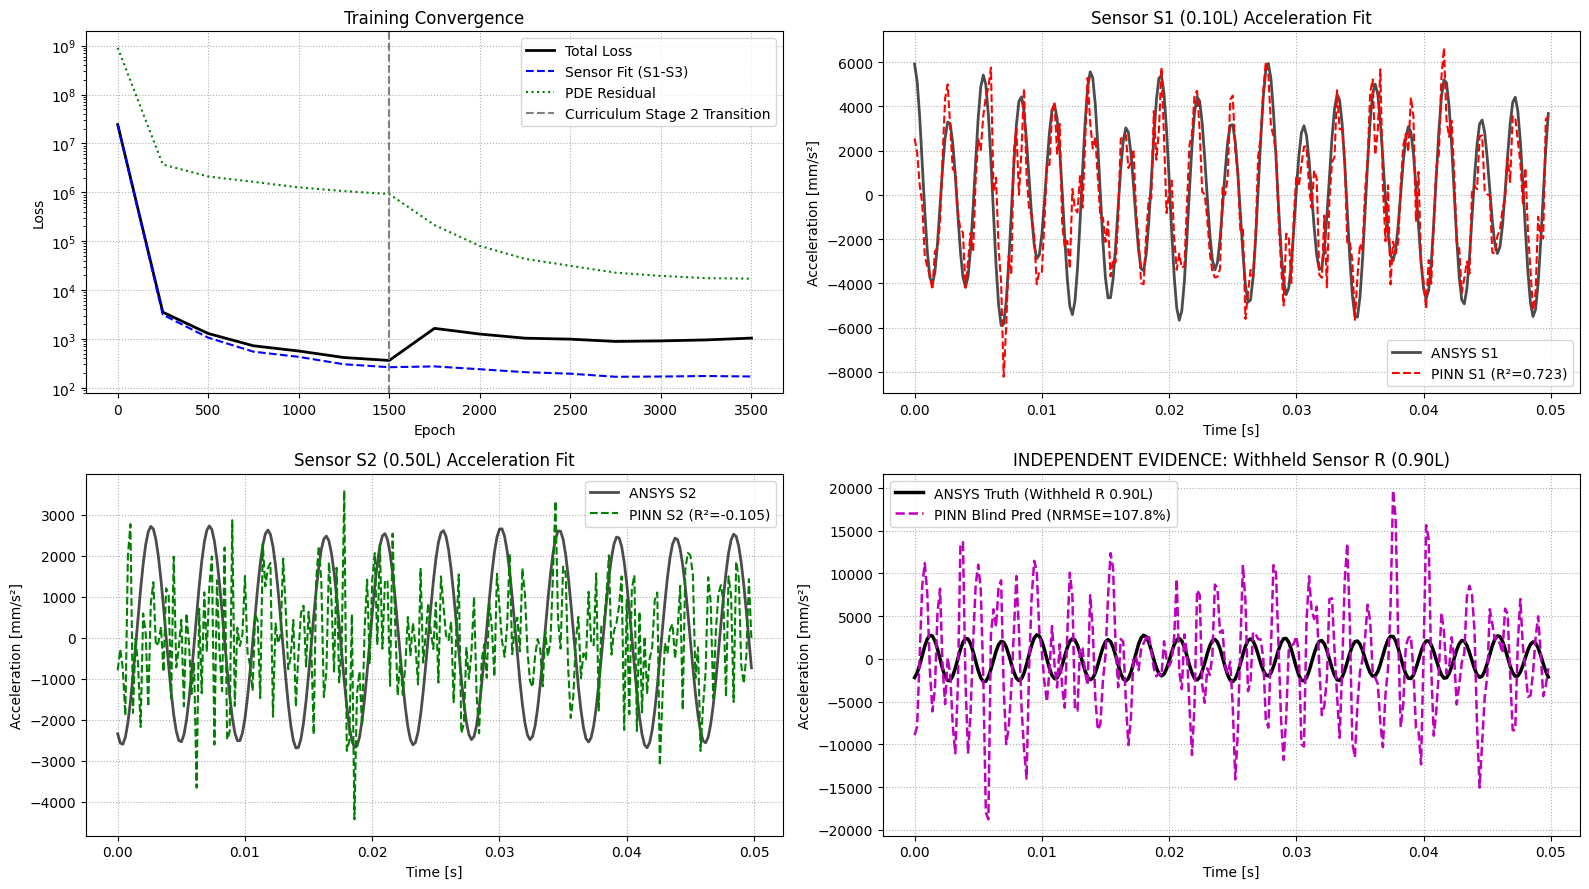

In [7]:
# Cell 7: Quantitative Evaluation Dashboard (NRMSE, R^2, and Withheld Sensor R at 0.90L)
model.eval()
t_eval = torch.tensor(ansys_data['t_hat'], device=device, requires_grad=True)
t_sec = ansys_data['time_sec']
num_pts = len(t_sec)

sensors = [
    ('s1', params.x_s1, 'Sensor S1 (0.10L)'),
    ('s2', params.x_s2, 'Sensor S2 (0.50L)'),
    ('s3', params.x_s3, 'Sensor S3 (0.80L)'),
    ('sR', params.x_sR, 'Withheld Sensor R (0.90L)')
]

a_pred = {}
metrics = {}
print("="*75)
print(f"FORWARD MODEL EVALUATION SUMMARY ({RUN_CASE.upper()})")
print("="*75)
print(f"{'Channel':<15} | {'Location':<10} | {'Role':<18} | {'NRMSE (%)':<10} | {'R^2 Score':<10}")
print("-"*75)

for key, x_phys, label in sensors:
    x_t = torch.full((num_pts, 1), x_phys / params.L, device=device, requires_grad=True)
    w = model(x_t, t_eval)
    w_t = torch.autograd.grad(w, t_eval, torch.ones_like(w), create_graph=True, retain_graph=True)[0]
    w_tt = torch.autograd.grad(w_t, t_eval, torch.ones_like(w_t), create_graph=False, retain_graph=False)[0]

    pred = w_tt.detach().cpu().numpy() * (params.a_scale * 1e3) # mm/s^2
    a_pred[key] = pred
    truth = ansys_data['a_mm_s2'][key]

    rmse = float(np.sqrt(np.mean((pred - truth)**2)))
    span = float(np.max(truth) - np.min(truth))
    nrmse = (rmse / span) * 100.0

    ss_res = np.sum((truth - pred)**2)
    ss_tot = np.sum((truth - np.mean(truth))**2)
    r2 = 1.0 - (ss_res / ss_tot)

    role = "Training Channel" if key != 'sR' else "WITHHELD VALIDATION"
    print(f"{key.upper():<15} | {x_phys/params.L:.2f}L       | {role:<18} | {nrmse:8.2f}%  | {r2:9.4f}")
    metrics[key] = {'nrmse': nrmse, 'r2': r2}
print("="*75)

# 4-Panel Evaluation Diagnostic Figure
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
axes[0, 0].semilogy(history['epoch'], history['total'], 'k-', lw=2, label='Total Loss')
axes[0, 0].semilogy(history['epoch'], history['sensor_data'], 'b--', label='Sensor Fit (S1-S3)')
axes[0, 0].semilogy(history['epoch'], history['pde'], 'g:', label='PDE Residual')
axes[0, 0].axvline(1500, color='gray', linestyle='--', label='Curriculum Stage 2 Transition')
axes[0, 0].set_title('Training Convergence'); axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('Loss'); axes[0, 0].grid(True, ls=':'); axes[0, 0].legend()

n_pts = min(250, len(t_sec))
axes[0, 1].plot(t_sec[:n_pts], ansys_data['a_mm_s2']['s1'][:n_pts], 'k-', lw=2, alpha=0.7, label='ANSYS S1')
axes[0, 1].plot(t_sec[:n_pts], a_pred['s1'][:n_pts], 'r--', lw=1.5, label=f"PINN S1 (R²={metrics['s1']['r2']:.3f})")
axes[0, 1].set_title('Sensor S1 (0.10L) Acceleration Fit'); axes[0, 1].set_xlabel('Time [s]'); axes[0, 1].set_ylabel('Acceleration [mm/s²]'); axes[0, 1].grid(True, ls=':'); axes[0, 1].legend()

axes[1, 0].plot(t_sec[:n_pts], ansys_data['a_mm_s2']['s2'][:n_pts], 'k-', lw=2, alpha=0.7, label='ANSYS S2')
axes[1, 0].plot(t_sec[:n_pts], a_pred['s2'][:n_pts], 'g--', lw=1.5, label=f"PINN S2 (R²={metrics['s2']['r2']:.3f})")
axes[1, 0].set_title('Sensor S2 (0.50L) Acceleration Fit'); axes[1, 0].set_xlabel('Time [s]'); axes[1, 0].set_ylabel('Acceleration [mm/s²]'); axes[1, 0].grid(True, ls=':'); axes[1, 0].legend()

axes[1, 1].plot(t_sec[:n_pts], ansys_data['a_mm_s2']['sR'][:n_pts], 'k-', lw=2.5, label='ANSYS Truth (Withheld R 0.90L)')
axes[1, 1].plot(t_sec[:n_pts], a_pred['sR'][:n_pts], 'm--', lw=1.8, label=f"PINN Blind Pred (NRMSE={metrics['sR']['nrmse']:.1f}%)")
axes[1, 1].set_title('INDEPENDENT EVIDENCE: Withheld Sensor R (0.90L)'); axes[1, 1].set_xlabel('Time [s]'); axes[1, 1].set_ylabel('Acceleration [mm/s²]'); axes[1, 1].grid(True, ls=':'); axes[1, 1].legend()
plt.tight_layout()
plt.show()

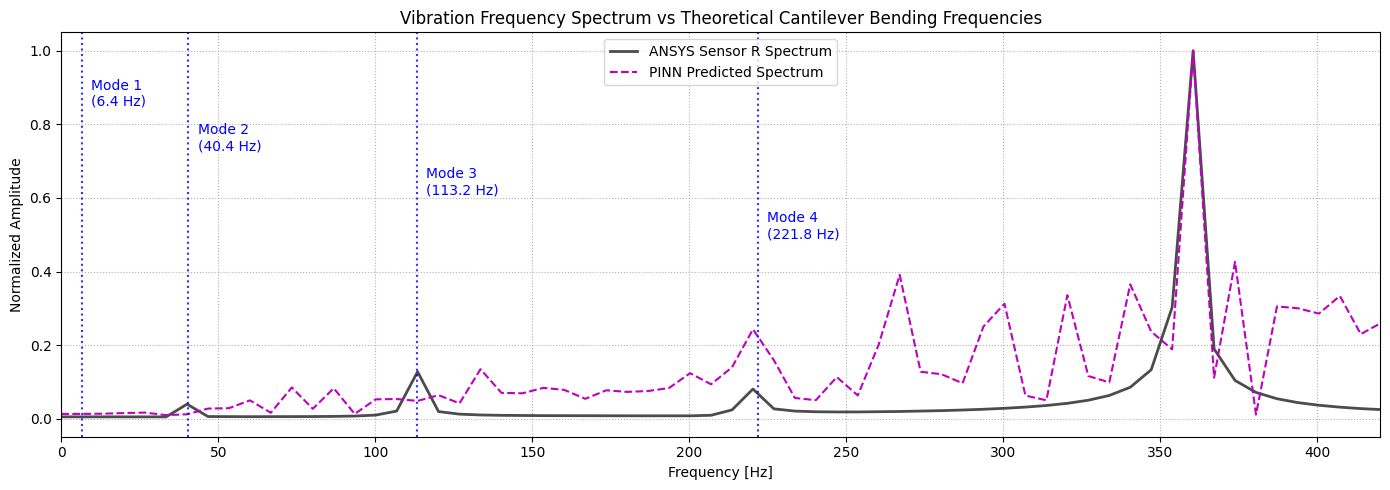

In [8]:
# Cell 8: Modal Spectral Check (FFT Comparison vs. Analytical Frequencies)
dt = ansys_data['dt']
fs = 1.0 / dt
n_fft = len(t_sec)
freqs = np.fft.rfftfreq(n_fft, d=dt)

fft_truth_R = np.abs(np.fft.rfft(ansys_data['a_mm_s2']['sR'].flatten()))
fft_pred_R  = np.abs(np.fft.rfft(a_pred['sR'].flatten()))

plt.figure(figsize=(14, 5))
plt.plot(freqs, fft_truth_R / np.max(fft_truth_R), 'k-', lw=2, alpha=0.7, label='ANSYS Sensor R Spectrum')
plt.plot(freqs, fft_pred_R / np.max(fft_pred_R), 'm--', lw=1.5, label='PINN Predicted Spectrum')

# Mark theoretical cantilever modes
for i, f_m in enumerate(params.natural_freqs_hz[:4]):
    plt.axvline(f_m, color='blue', linestyle=':', alpha=0.8)
    plt.text(f_m + 3, 0.85 - (i*0.12), f'Mode {i+1}\n({f_m:.1f} Hz)', color='blue', fontsize=10)

plt.xlim(0, 420)
plt.xlabel('Frequency [Hz]')
plt.ylabel('Normalized Amplitude')
plt.title('Vibration Frequency Spectrum vs Theoretical Cantilever Bending Frequencies')
plt.grid(True, ls=':')
plt.legend()
plt.tight_layout()
plt.show()

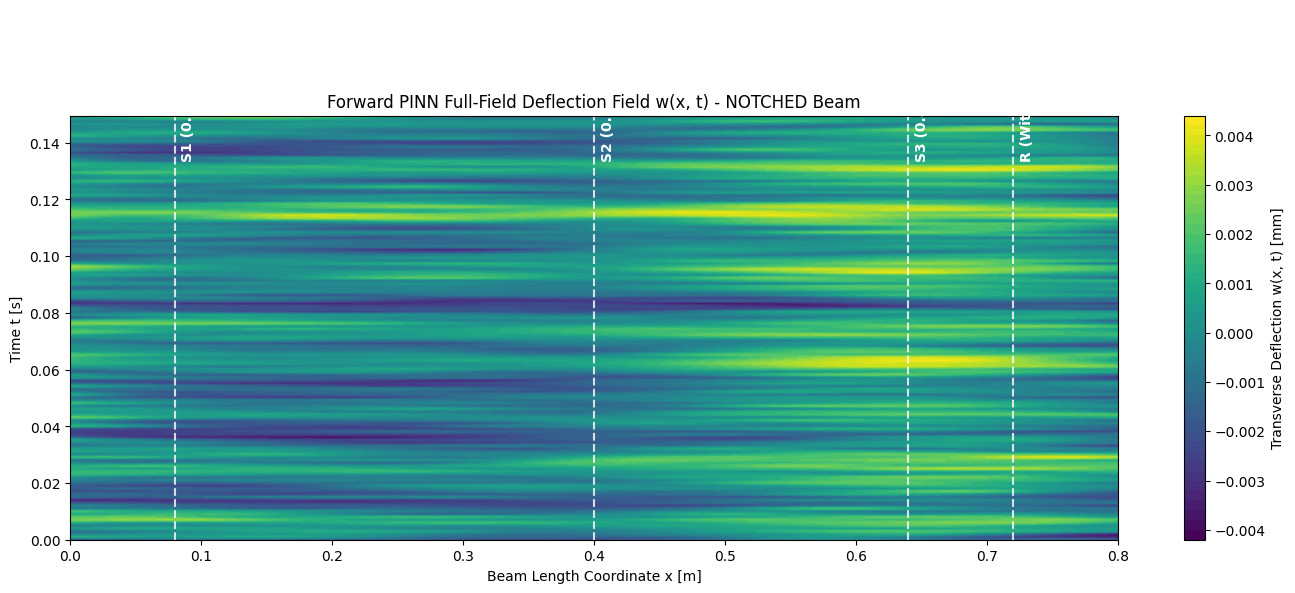

In [9]:
# Cell 9: Full-Field Continuous Spatio-Temporal Field Reconstruction w(x, t)
nx, nt = 120, 150
x_eval = np.linspace(0, 1, nx, dtype=np.float32)
t_eval = np.linspace(0, float(ansys_data['t_hat'][-1, 0]), nt, dtype=np.float32)
X, T = np.meshgrid(x_eval, t_eval)

X_t = torch.tensor(X.flatten().reshape(-1, 1), device=device)
T_t = torch.tensor(T.flatten().reshape(-1, 1), device=device)
with torch.no_grad():
    w_field_mm = model(X_t, T_t).cpu().numpy().reshape(nt, nx) * (params.w_scale * 1e3)

plt.figure(figsize=(14, 6))
c = plt.contourf(x_eval * params.L, t_eval * params.t_scale, w_field_mm, 50, cmap='viridis')
cb = plt.colorbar(c)
cb.set_label('Transverse Deflection w(x, t) [mm]')

for s_name, s_coord in [('S1 (0.10L)', params.x_s1), ('S2 (0.50L)', params.x_s2), ('S3 (0.80L)', params.x_s3), ('R (Withheld, 0.90L)', params.x_sR)]:
    plt.axvline(s_coord, color='white', linestyle='--', alpha=0.8)
    plt.text(s_coord + 0.005, float(t_eval[-1]*params.t_scale)*0.9, s_name, color='white', rotation=90, fontweight='bold')

plt.xlabel('Beam Length Coordinate x [m]')
plt.ylabel('Time t [s]')
plt.title(f'Forward PINN Full-Field Deflection Field w(x, t) - {RUN_CASE.upper()} Beam')
plt.tight_layout()
plt.show()

In [10]:
from pathlib import Path

model_path= Path("Models")
model_path.mkdir(parents= True, exist_ok= True)

model_name = "forwardModel_itr2.pth"
model_savePath = model_path / model_name

print(f"saving your model to: {model_savePath}")
torch.save(obj=model.state_dict(), f= model_savePath)

saving your model to: Models/forwardModel_itr2.pth
